<a href="https://colab.research.google.com/github/JasonLou622/Hospital-readmissions-analysis/blob/main/diabetes_readmission_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd, sqlite3 # pandas works with tables
                             # sqlite 3 lets Python talk to a SQL database.

df = pd.read_csv("diabetic_data.csv") # dataframe AS df
# reads the csv file into Python as a table.

print(df.shape) # df.shape gives (rows, columns)
df.info()       # info() lists each column with its count of non-empty values
                # and its type.
                # 'object' means text, 'int64' means whole numbers.

(101766, 50)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int

Notes:
1. 'max_glu_serum' has only 5346 values and 'A1Cresult' only 17,018, out of 101,766 rows. Most of those tests are missing.

In [6]:
conn = sqlite3.connect("diabetes.db")
# creates a small database file and opens a connection to it.

df.to_sql("diabetes_data", conn, if_exists="replace", index=False)
# copies the table from diabetic_data.csv into the dataset df as a SQL table
# name as diabetes_data
# conn is like an address (or phone line) used to talk to the database.
# if_exists="replace" means overwritte
# 'index=False' means don't add an extra row-number column

print(pd.read_sql("SELECT * FROM diabetes_data LIMIT 5", conn))
# pd.read_sql a pandas function
# use and run the context in the double quotes as a snippet of SQL code
# conn, connects to the table (diabetes_data) in diabetes.db

   encounter_id  patient_nbr             race  gender      age weight  \
0       2278392      8222157        Caucasian  Female   [0-10)      ?   
1        149190     55629189        Caucasian  Female  [10-20)      ?   
2         64410     86047875  AfricanAmerican  Female  [20-30)      ?   
3        500364     82442376        Caucasian    Male  [30-40)      ?   
4         16680     42519267        Caucasian    Male  [40-50)      ?   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                  6                        25                    1   
1                  1                         1                    7   
2                  1                         1                    7   
3                  1                         1                    7   
4                  1                         1                    7   

   time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0                 1  ...          No      No                   No

Notes:
1. The column 'weight' shows '?' in the column 'weight'. The dataset uses '?' for missing values.

In [7]:
# Analysis 1: Measures the total number of patients were readmitted in under 30 days
query = """
SELECT readmitted, COUNT(*) AS encounters
FROM diabetes_data
GROUP BY readmitted;
"""
print(pd.read_sql(query, conn))


# In the triple quotes, allowing to write a multi-line piece of text.
# Python holds it as a text.
# 'pd.read_sql' sends that text through the connection, runs it,
# and brings the answer back as a table.

  readmitted  encounters
0        <30       11357
1        >30       35545
2         NO       54864


Notes:
1. Readmissions: 11,357 encounters ('<30', about 11%) were followed by a readmission within 30 days, 35,545 after 30 days('>30', about 35%), and 54,864 not at all ('NO', about 54%). The three add up to 101,766, so nothing was lost.

In [8]:
# Analysis 2: Examines the average time in hospital for each age group
query = '''
SELECT age,
       COUNT(*) AS encounters,
       ROUND(AVG(time_in_hospital), 2) AS Average_time_in_hospital
FROM diabetes_data
GROUP BY age;
'''
print(pd.read_sql(query, conn))

        age  encounters  Average_time_in_hospital
0    [0-10)         161                      2.55
1   [10-20)         691                      3.19
2   [20-30)        1657                      3.56
3   [30-40)        3775                      3.80
4   [40-50)        9685                      4.04
5   [50-60)       17256                      4.13
6   [60-70)       22483                      4.38
7   [70-80)       26068                      4.59
8   [80-90)       17197                      4.81
9  [90-100)        2793                      4.76


Notes:
1. Found that average hospital stay rises with age, from about 2.55 (lowest) to 4.81 days (highest).

In [10]:
# Analysis 3: Measures the number of patients in each age group were readmitted within 30 days.
query = '''
SELECT age,
       COUNT(*) AS encounters_readmitted_30d
FROM diabetes_data
WHERE readmitted = '<30'
GROUP BY age;
'''
print(pd.read_sql(query, conn))

        age  encounters_readmitted_30d
0    [0-10)                          3
1   [10-20)                         40
2   [20-30)                        236
3   [30-40)                        424
4   [40-50)                       1027
5   [50-60)                       1668
6   [60-70)                       2502
7   [70-80)                       3069
8   [80-90)                       2078
9  [90-100)                        310


Notes:
1. Age group [70-80) has the most encounters followed by a readmission within 30 days (3,069), but it is also the largest group (26,068 encounters), so the rate is a faier comparison than the count.

        age  encounters  readmitted_30d  pct_readmitted_30d
0    [0-10)         161               3                 1.9
1   [10-20)         691              40                 5.8
2   [20-30)        1657             236                14.2
3   [30-40)        3775             424                11.2
4   [40-50)        9685            1027                10.6
5   [50-60)       17256            1668                 9.7
6   [60-70)       22483            2502                11.1
7   [70-80)       26068            3069                11.8
8   [80-90)       17197            2078                12.1
9  [90-100)        2793             310                11.1


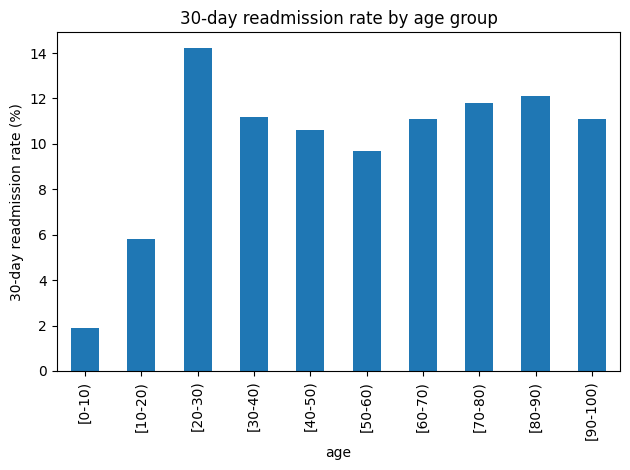

In [11]:
# Analysis 4: Examines the 30-day readmission rate in each age group.
query = '''
SELECT
  age,
  COUNT(*) AS encounters,
  SUM(1) FILTER (WHERE readmitted = '<30') AS readmitted_30d,
  ROUND(100.0 *
        (SUM(1) FILTER (WHERE readmitted = '<30')) / COUNT(*),
        1
  ) AS pct_readmitted_30d
FROM diabetes_data
GROUP BY age
ORDER BY age;
'''
result = pd.read_sql(query, conn)
print(result)

import matplotlib.pyplot as plt
result.plot(x="age", y="pct_readmitted_30d", kind="bar", legend=False)
plt.ylabel("30-day readmission rate (%)")
plt.title("30-day readmission rate by age group")
plt.tight_layout()
plt.show()

Notes:
1. The lowest percentage of readmitted in 30 days is followed by age group [0-10), and the highest comes from age group [20-30).
2. Notice: Age group [0-10) has 3 out of 161 encounters (lowest) were readmitted within 30 days; age group [70-80) has the most encounters (3,069 out of 26,068); age group [10-20) are 236 out of 1,657 encounters.
3. The most common percentage of 30-day readmission by age is around 11.1%.

    time_in_hospital  encounters  pct_readmitted_30d
0                  1       14208                 8.2
1                  2       17224                 9.9
2                  3       17756                10.7
3                  4       13924                11.8
4                  5        9966                12.0
5                  6        7539                12.6
6                  7        5859                12.8
7                  8        4391                14.2
8                  9        3002                13.7
9                 10        2342                14.3
10                11        1855                10.5
11                12        1448                13.3
12                13        1210                12.3
13                14        1042                13.0
Index(['time_in_hospital', 'encounters', 'pct_readmitted_30d'], dtype='object')


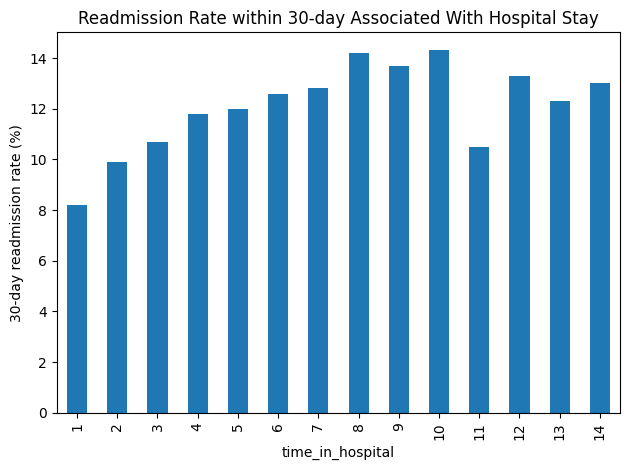

In [13]:
# Analysis 5: Examines whether a longer hospital stay is associated with patient readmission.
query = '''
SELECT
       time_in_hospital,
       COUNT(*) AS encounters,
       ROUND(100.0 *
             SUM(1) FILTER (WHERE readmitted = '<30') / COUNT(*),
             1
       ) AS pct_readmitted_30d
FROM diabetes_data
GROUP BY time_in_hospital
ORDER BY time_in_hospital
'''
result = pd.read_sql(query, conn)
print(result)

# print(result.columns)
result.plot(x="time_in_hospital", y="pct_readmitted_30d", kind="bar", legend=False)
plt.ylabel("30-day readmission rate (%)")
plt.title("Readmission Rate within 30-day Associated With Hospital Stay")
plt.tight_layout()
plt.show()

Notes:
1. This outcome indicates encounters who stay in hospital longer are more likely readmitted in 30 days.
2. Noticed the percentage drops rapidly by hospital staying day 11th. Adding 'COUNT(*) AS encounters' to check out whether the percentage of readmission within 30-day is associated with the number of encounters. If the number of encounters of day 11th is small than other cohorts, its percentage is less accurate, then it may be the reason that it drops.
3. The number of encounters under hospital staying day 11th doesn't drop rapidly. Therefore, the reason of the percentage drops rapidly by hospital staying day 11th is no clear, but single cohort doesn't affect the conclusion that hospital stay days associates with the readmission rate within 30 dyas.

In [14]:
# Analysis 6: Examines if the number of earlier inpatient visits (number_inpatient) relates to readmission.
query = '''
SELECT number_inpatient,
       COUNT(*) AS encounters,
       ROUND(100.0 *
             COUNT(*) FILTER (WHERE readmitted = '<30') / COUNT(*),
             1
       ) AS pct_readmitted_30d
FROM diabetes_data
GROUP BY number_inpatient
HAVING COUNT(*) >= 100
ORDER BY number_inpatient;
'''

print(pd.read_sql(query, conn))

   number_inpatient  encounters  pct_readmitted_30d
0                 0       67630                 8.4
1                 1       19521                12.9
2                 2        7566                17.4
3                 3        3411                20.3
4                 4        1622                23.6
5                 5         812                31.4
6                 6         480                34.6
7                 7         268                35.4
8                 8         151                44.4
9                 9         111                42.3


Notes:

The 30-day readmission rate rises steadily, from 8.4% for patients without earlier hospital stays (67630 encounters) to 44.4% for patients with eight days stay (151 encounters). Which is about five times higher.

In [19]:
# Analysis 7: Determines whether medical_specialty associates with the 30-day readmission rate.
query = '''
SELECT medical_specialty,
       COUNT(*) AS encounters,
       COUNT(*) FILTER (WHERE readmitted = '<30') AS readmitted_30d,
       ROUND(100.0 *
             COUNT(*) FILTER (WHERE readmitted = '<30') / COUNT(*),
             1
       ) AS pct_readmitted_30d
FROM diabetes_data
WHERE medical_specialty != '?'
GROUP BY medical_specialty
HAVING COUNT(*) >= 500
ORDER BY pct_readmitted_30d DESC;
'''

print(pd.read_sql(query, conn))

                  medical_specialty  encounters  readmitted_30d  \
0                        Nephrology        1613             248   
1                  Surgery-Vascular         533              74   
2                        Psychiatry         854             104   
3            Family/GeneralPractice        7440             883   
4                  InternalMedicine       14635            1646   
5                  Emergency/Trauma        7565             846   
6                   Surgery-General        3099             342   
7                       Pulmonology         871              96   
8                  Gastroenterology         564              62   
9                       Orthopedics        1400             151   
10                          Urology         685              68   
11                      Radiologist        1140             103   
12                       Cardiology        5352             425   
13       Orthopedics-Reconstructive        1233              9

Notes:

1. Nephrology category has the highest 30-day readmission rate (15.4), and ObstetricsandGynecology has the lowest (4.8).
2. InternalMedicine has the most encounters (14,635), seven specialties have at least 500 encounters.

  A1Cresult  encounters  readmitted_30d  pct_readmitted_30d
0      None       84748            9681                11.4
1        >7        3812             383                10.0
2        >8        8216             811                 9.9
3      Norm        4990             482                 9.7


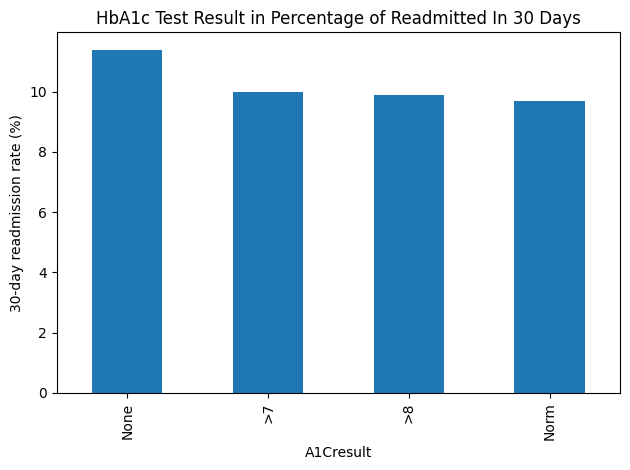

In [20]:
# Analysis 8: Determines whether the HbA1c test relates to readmission.
query = '''
SELECT A1Cresult,
       COUNT(*) AS encounters,
       COUNT(*) FILTER (WHERE readmitted = '<30') AS readmitted_30d,
       ROUND(100.0 *
             COUNT(*) FILTER (WHERE readmitted = '<30') / COUNT(*),
             1
       ) AS pct_readmitted_30d
FROM diabetes_data
GROUP BY A1Cresult
'''
print(pd.read_sql(query, conn))

result = pd.read_sql(query, conn)
# print(result.columns)
result.plot(x="A1Cresult", y="pct_readmitted_30d", kind="bar", legend=False)
plt.ylabel("30-day readmission rate (%)")
plt.title("HbA1c Test Result in Percentage of Readmitted In 30 Days")
plt.tight_layout()
plt.show()

Notes:
1. Suggests that having an HbA1c test is associated with a lower likehood of 30-day readmission rate, as only 9.9% ((129+324)/(1135+3462) approximates to 9.85%) of encounters who received an HbA1c test were readmitted within 30 dyas. In contrast, encounters who did not take this test had a higher rate (11.4%) of readmission within 30 days. Furthermore, the total number of readmitted encounters (84,748) who did not receive an HbA1c test far exceeds the total number of readmitted encounters (12,028) who did receive this test.


In [31]:
# Clean the data and note its limits
df = df.replace("?", pd.NA)
print(df.isna().sum().sort_values(ascending=False).head(10))
# Shows which columns have the most missing values.


weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
patient_nbr              0
dtype: int64


Indicating columns weihght, max_gul_serum, and A1Cresult have the most missing values.

In [32]:
# Check the IDS_mapping.csv file
df1 = pd.read_csv("IDS_mapping.csv")
df1.shape
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67 entries, 0 to 66
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   admission_type_id  65 non-null     object
 1   description        62 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [33]:
# Find descriptions containing expired or hospice
filtered_df1 = df1[ # creates a new filtered subset dataframe by taking out rows out of df1 -- the IDS_mapping lookup table.
    df1["description"].str.contains(  # .str treats every row/entry in this column as string text
                                      # .contains(...) a pandas string method that checks if a specific word or pattern exists
                                      # inside each text row/entry.
        "expired|hospice",            # spaces matter, pandas will literally search for the phrase "expired " or "  Hospice".
        case=False,                   # search case-insensitive
        na=False                      # Tells pandas how to handle missing values like (NaN or empty cells) in this column.
                                      # treats any missing cell as a "False" (don't match this row), so the code doesn't crash.
    )
]
filtered_df1

,admission_type_id,description
20,11,Expired
22,13,Hospice / home
23,14,Hospice / medical facility
28,19,"Expired at home. Medicaid only, hospice."
29,20,"Expired in a medical facility. Medicaid only, ..."
30,21,"Expired, place unknown. Medicaid only, hospice."
66,26,Transfer from Hospice


Notes:

Finding some encounters are ending in death or hospice.

In [34]:
# Excludes these patients from readmission cohorts

query = '''
SELECT COUNT(*) AS encounters_to_remove
FROM diabetes_data
WHERE discharge_disposition_id IN (11, 13, 14, 19, 20 ,21);
'''

print(pd.read_sql(query, conn))

   encounters_to_remove
0                  2423


Notes:

Excludes these patients from readmission cohorts, since they will always count as "not readmitted", lowering readmission rates and misleading the final analysis result.

In [35]:
# Analysis 9: compares with the overall 30-day readmission rate after exclusion

# first line return a new column
# UNION ALL takes the results of two SELECT queries and stacks them together into one table. Keeping all rows.
# Plain UNION does the same but removes duplicates.
query = '''
SELECT 'all encounters' AS version,
       COUNT(*) AS encounters,
       ROUND(100.0 * COUNT(*) FILTER (WHERE readmitted = '<30') / COUNT(*), 1) AS pct_readmitted_30d
FROM diabetes_data
UNION ALL
SELECT 'excluding expired/hospice',
       COUNT(*),
       ROUND(100.0 * COUNT(*) FILTER  (WHERE readmitted = '<30') / COUNT(*), 1)
FROM diabetes_data
WHERE discharge_disposition_id NOT IN (11, 13, 14, 19, 20, 21);
'''

print(pd.read_sql(query, conn))

                     version  encounters  pct_readmitted_30d
0             all encounters      101766                11.2
1  excluding expired/hospice       99343                11.4


Notes:

The number of encounters reduces from 101,766 to 99,343 (2,423 in difference), and the percentage of 30-day readmission rises slightly from 11.2% to 11.4%.

In [36]:
# Analysis 10: Rerun the analysis of readmission rate with age groups
query = '''
SELECT age,
       COUNT(*) AS encounters,
       COUNT(*) FILTER (WHERE readmitted = '<30') AS encounters_readmitted_30d,
       ROUND(100.0 * COUNT(*) FILTER (WHERE readmitted = '<30') / COUNT(*), 1) AS pct_readmitted_30d
FROM diabetes_data
WHERE discharge_disposition_id NOT IN (11, 13, 14, 19, 20, 21)
GROUP BY age
ORDER BY age;
'''

print(pd.read_sql(query, conn))

        age  encounters  encounters_readmitted_30d  pct_readmitted_30d
0    [0-10)         160                          3                 1.9
1   [10-20)         690                         40                 5.8
2   [20-30)        1649                        236                14.3
3   [30-40)        3764                        424                11.3
4   [40-50)        9607                       1024                10.7
5   [50-60)       17060                       1667                 9.8
6   [60-70)       22059                       2493                11.3
7   [70-80)       25331                       3054                12.1
8   [80-90)       16434                       2065                12.6
9  [90-100)        2589                        308                11.9


Notes:

After this exclusion, the 30-day readmission rates are slightly higher, especially for oldest age groups (for instance, age group [80-90) rasies from 12.1% to 12.6%, and [90-100) rasies from 11.1% to 11.9%.)

In [38]:
# Analysis 11: Re-examines if the number of earlier inpatient visits (number_inpatient) relates to readmission.
query = '''
SELECT
  number_inpatient,
  COUNT(*) AS encounters,
  ROUND(100.0 *
        COUNT(*) FILTER (WHERE readmitted = '<30') / COUNT(*),
        1
  ) AS pct_readmitted_30d
FROM diabetes_data
WHERE discharge_disposition_id NOT IN (11, 13, 14, 19, 20, 21)
GROUP BY number_inpatient
HAVING COUNT(*) >= 100
ORDER BY number_inpatient;
'''

print(pd.read_sql(query, conn))


   number_inpatient  encounters  pct_readmitted_30d
0                 0       66245                 8.6
1                 1       18984                13.3
2                 2        7300                17.9
3                 3        3271                21.0
4                 4        1574                24.1
5                 5         791                32.0
6                 6         474                34.8
7                 7         262                36.3
8                 8         145                46.2
9                 9         109                43.1


After excluding encounters ending in death or hospice, the 30-day readmission rates changed slightly (for instance, from 8.4% rises to 8.6% for patients with no earlier hospital stay, from 44.4% to 46.2% for patients with eight), so the exclusion doesn't change previous conclusions.

In [39]:
# Re-examines whether medical_specialty has the highest 30-day readmission rate.
query = '''
SELECT
  medical_specialty,
  COUNT(*) AS encounters,
  ROUND(100.0 * COUNT(*) FILTER (WHERE readmitted = '<30') / COUNT(*), 1) AS pct_readmitted_30d
FROM diabetes_data
WHERE discharge_disposition_id NOT IN (11, 13, 14, 19, 20, 21)
  AND medical_specialty <> '?'
GROUP BY medical_specialty
HAVING COUNT(*) >= 500
ORDER BY pct_readmitted_30d DESC;
'''

print(pd.read_sql(query, conn))


                  medical_specialty  encounters  pct_readmitted_30d
0                        Nephrology        1539                16.1
1                  Surgery-Vascular         525                14.1
2                        Psychiatry         853                12.2
3            Family/GeneralPractice        7252                12.1
4                  InternalMedicine       14237                11.5
5                  Emergency/Trauma        7419                11.4
6                  Gastroenterology         538                11.3
7                   Surgery-General        3059                11.2
8                       Pulmonology         854                11.2
9                       Orthopedics        1392                10.8
10                          Urology         682                 9.8
11                      Radiologist        1121                 9.1
12                       Cardiology        5279                 8.0
13       Orthopedics-Reconstructive        1230 

Notes:

Nephrology is highest at 16.1%, against an overall rate of 11.4%, while ObstetricsandGynecology (4.8%) and Surgery-Cardiovascular/Thoracic (6.7%) are lowest. There are seven specialties have at least 500 encounters, and about half the rows have no specialty recorded.

Summary:

Across all (101,766) hospital encounters, about 11% were readmitted within 30 days, and 35% were readmitted after 30 days. The readmission rates were similar across adult age groups (about 10-12%) but were associated with the length of staying days, rising from 8.2% (lowest) at day one to 14.3% (highest)at day ten. The association between HbA1c test and readmission rate was no strong, since encounters (12,028) with HbA1c test had a slightly lower percentage of 30-day readmission (about 9.9%) than those without (11.4%). Furthermore, the 30-day readmission rate rises steadily from 8.8.6% for patients with no earlier hospital stays (66,245 encounters) to 46.2% for patients with eight days earlier hospital stay (145 encounters), which is about five time higher. Nephrology has the highest rate (16.1%) of 30-day readmission, along an overall rate of 11.4%, while ObstetricsandGynecology (4.8%) and Surgery-Cardiovascular/Thoracic (6.7%) are lowest, with having at least 500 encounters. By checking out IDS_mapping.csv dataset, found some encounters are ending in death or hospice that may mislead the previous conclusions. After excluding 2423 encounters and re-analyzing all of result, the exclusion does not change the all of previous conclusions.